# 401 - Foundations of Convolutional Neural Networks

In [1]:
import json

import numpy as np
from src.datasets import load_examples_mnist, expanded_training_pairs
from src.network import Network, FullyConnectedLayer, ConvPoolLayer
import matplotlib.pyplot as plt
from src.optimizers import AdamOptimizer, MomentumOptimizer
%load_ext autoreload
%autoreload 2

## Revisiting MNIST - Shallow Network

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

training_data = load_examples_mnist(n_samples=60000)
X_train, X_val, y_train, y_val = train_test_split(*training_data, test_size=1/6, random_state=42)

net = Network(
    sizes = [784, 100, 10],
    activation_functions=["sigmoid", "sigmoid"],
    cost = "cross_entropy",
    max_epochs=60,
    mini_batch_size=10,
    learning_rate=2.5e-2,
    penalty="l2",
    alpha=5.0,
    monitor_accuracy=True,
    monitor_cost=True,
)

binarize = LabelBinarizer()

X_train_t = X_train.T / 255
y_train_t = binarize.fit_transform(y_train[:, np.newaxis]).T
X_val_t = X_val.T / 255
y_val_t = binarize.transform(y_val[:, np.newaxis]).T

net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
print(f"Training accuracy: {net.score(X_train_t, y_train_t):.1%}")
print(f"Validation accuracy: {net.score(X_val_t, y_val_t):.1%}")

Training accuracy: 100.0%
Validation accuracy: 98.0%


## Introducing Convolutional Networks

In classifying images with fully connected layers, we considered pixels as a single vertical stack of neurons and connected them to the hidden neurons and let the network learn the weights.

The problem with this is that it does not take into account the spatial structure of the image. How the pixels are related in space were not considered.

ConvNets gives a way to learn the spacial structure of the image by considering pixels as an array of neurons, which seems to be a more natural way of learning images.





### Local Receptive Fields
- A small region of the 28px x 28px image, called a *local receptive field*, is connected to a hidden neuron.
- Each connection learns a weight.
- To cover the entire image, start with the topmost leftmost small region and then slide by one step to the right. After reaching the topmost rightmost small region, slide one step down and, once again, slide from the leftmost small region up to the rightmost small region. Repeat.

| 1. Local Receptive Field | 2. Start at the topmost leftmost region | 3. Slide along the height and width to form the first hidden layer |
| --- | --- | --- |
| ![nielsen-1](references/nielsen-cnn-img1.png)</br> | ![nielsen-2](references/nielsen-cnn-img2.png) | ![nielsen-3](references/nielsen-cnn-img3.png) |
*\*images were taken from Nielsen's book*

**Example.**</br>
original shape: 28x28 </br>
small region: 5x5 <br>
number of slides from left to right: 24 (including the start) </br>
number of slides from top to bottom: 24 (including start) </br>
shape of resulting hidden layer: 24 x 24 </br>

Each hidden neuron is connected to a 5x5 region via 5x5 weights and one bias term, and **the 5x5 weights and 1 bias is shared among hidden neurons.**
$$
\mathbf{A} = \sigma(\mathbf{W}\circ \mathbf{X} + b)
$$
Where $\circ$ is the convolution operation defined as follows.
$$
(\mathbf{W}\circ \mathbf{X})[n,m] = \sum_{k_1,k_2 = -K}^{K} \mathbf{W}[k_1,k_2]\mathbf{X}[n+k_1,m+k_2]
$$
Because the weights $\mathbf{W}$ are shared, the hidden neurons learn the same feature of the image: A vertical edge, a horizontal edge, etc. The difference between a hidden neuron and another is that they learn the same feature in a different area of the image.

The mapping from the image to the hidden layer is often called a **feature map**. The weights $\mathbf{W}$ and the bias $b$ are called the **shared weights** and **shared bias**, respectively. $\mathbf{W},\, b$ are said to form a **kernel** or a **filter**.

Often more than one feature map is needed to be able to recognize images.

### Pooling Layers

After the feature maps, the activations are propagated into a **pooling layer** as a way to summarize (condense) the information obtained. The hidden neurons learn if a feature exists in the corresponding local receptive field of the image and its exact positional location. The idea is that pooling provides an indicator that a feature exists in a local receptive field, but throw away the information about positional location as it is not as important.

Similar to the feature map from the input layer to the hidden layer, the feature map from the hidden layer to the pooling layer takes a small region of the hidden layer and applies an aggregate function.

An aggregate function that is often used is $f(\cdot) = \max_{a_{p,q}}(\cdot)$ and we call this procedure of pooling **max-pooling**.

**Example.** </br>
Take a 2x2 subregion from the hidden layer and find the maximum of the values of the activations in the 2x2 subregion. </br>
As before, start from the topmost leftmost 2x2 subregion and slide along the height and width of the hidden layer, except this time the stride length is equal to the shape of the subregion. </br>
With a 24x24 hidden layer, the shape of the pooling layer would be 12x12.

![nielsen-img4](references/nielsen-cnn-img4.png)</br>
*\*image taken from Nielsen's book*

Topmost leftmost:
$$
\begin{align*}
    a^{(2)}_{0,0} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{l,m}
\end{align*}
$$

1,1-th pooling unit:
$$
\begin{align*}
    a^{(2)}_{1,1} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{1+l,1+m}
\end{align*}
$$

p,q-th pooling unit:
$$
\begin{align*}
    a^{(2)}_{p,q} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{p+l,q+m}
\end{align*}
$$

### CNN Architecture for MNIST

![my_net_01](assets/my_net_01.png)

For efficient implementation of the forward and backward pass, we apply a preprocessing step on the image/layer before passing to the feature map. The preprocessing step takes each local receptive field, flattens it into a column vector, and then stacks the local receptive fields side-by-side.

In [3]:
def extract_field(arr,pos,K):
    n,m = pos
    return arr[n-K:n+K+1,m-K:m+K+1]

def img2col(arr, field_shape:int, stride:int=1):
    lcr_list = []
    K = (field_shape-1)//2
    for n in range(K,arr.shape[0]-K, stride):
        for m in range(K,arr.shape[1]-K, stride):
            lcr = extract_field(arr, (n,m), K)
            lcr_list.append(lcr.reshape(-1,1,order="F"))
    return np.column_stack(lcr_list)

def conv2d(arr, kernel, pad_width:int):
    kernel_shape = kernel.shape[0]
    arr_padded = np.pad(arr, pad_width=pad_width, mode="constant", constant_values=0)
    arr2col = img2col(arr_padded, kernel_shape)
    filter2row = np.flip(kernel).copy().reshape(1, -1,order="F")
    n_out = arr_padded.shape[0] - kernel_shape + 1
    m_out = arr_padded.shape[1] - kernel_shape + 1
    return (filter2row @ arr2col).reshape(n_out, m_out)

#### Forward pass
Consider an image sample and a fixed kernel.

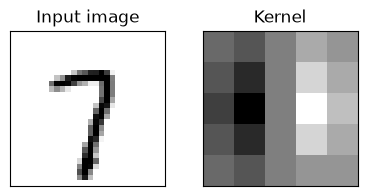

In [4]:
image_sample = X_train[2].reshape(28, 28)
kernel_ = np.array([     # Sobel kernel
    [1, 2, 0, -2, -1],
    [2, 4, 0, -4, -2],
    [3, 6, 0, -6, -3],
    [2, 4, 0, -4, -2],
    [1, 2, 0, -1, -1],
])
fig,axs = plt.subplots(1,2,figsize=(4,2),subplot_kw=dict(xticks=[],yticks=[]))
axs[0].imshow(image_sample/255, cmap="binary", interpolation="nearest")
axs[0].set_title("Input image")
axs[1].imshow(kernel_, cmap="binary", interpolation="nearest")
axs[1].set_title("Kernel")
plt.tight_layout()
plt.show()

The convolution will be obtained using the above implementation (`conv2d`) and pooling is done by downsampling the output of the convolution using Numpy functions.

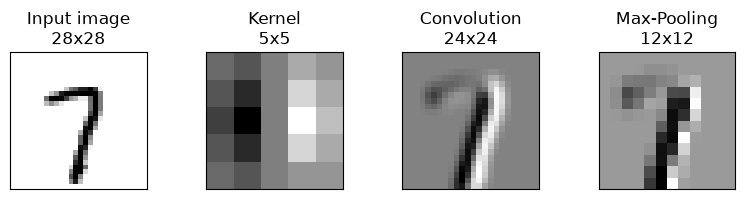

In [5]:
# Convolution
conv = conv2d(image_sample, kernel_, 0)

# Max-Pooling
pooling_shape = 2
pool = conv.reshape(conv.shape[0]//pooling_shape, pooling_shape, conv.shape[1]//pooling_shape, pooling_shape).max(axis=(1,3))

fig,axs = plt.subplots(1,4,figsize=(8,2),subplot_kw=dict(xticks=[],yticks=[]))
axs[0].imshow(image_sample/255, cmap="binary", interpolation="nearest")
axs[0].set_title(f"Input image\n{image_sample.shape[0]}x{image_sample.shape[1]}")
axs[1].imshow(kernel_, cmap="binary", interpolation="nearest")
axs[1].set_title(f"Kernel\n{kernel_.shape[0]}x{kernel_.shape[1]}")
axs[2].imshow(conv, cmap="binary", interpolation="nearest")
axs[2].set_title(f"Convolution\n{conv.shape[0]}x{conv.shape[1]}")
axs[3].imshow(pool, cmap="binary", interpolation="nearest")
axs[3].set_title(f"Max-Pooling\n{pool.shape[0]}x{pool.shape[1]}")
plt.tight_layout()

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Update:</strong> On second thought, I'm going to follow Nielsen's implementation: using a library that provides primitives for convolution forward and backward, and automatic differentiation. The library I'll be using is Pytorch! Most likely, I'll be using Pytorch anyway. So, I'll just translate some of Nielsen's implementation, based on Theano, to a Pytorch-based program.
</div>

In [31]:
from src.network import NeuralNet, ConvPoolLayer, FullyConnectedLayer, SoftMaxLayer
import torch
from torch.nn.functional import relu

device = 'mps'
X, y = load_examples_mnist(n_samples=60000)
X = (torch.from_numpy(X).float()/255).to(device)
y = torch.from_numpy(binarize.fit_transform(y[:,np.newaxis])).float().to(device)

X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:60000], y[50000:60000]

X_test, y_test = load_examples_mnist(n_samples=10000,
                                     images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                     labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')
X_test = (torch.from_numpy(X_test).float()/255).to(device)
y_test = torch.from_numpy(y_test).float().to(device)

In [141]:
results = {
    (1e-3,0.5): [[c.cpu() for c in val_cost], [s.cpu() for s in val_score]]
}

In [197]:
for eta in [3e-2, 5e-2, 7e-2]:
    net = NeuralNet([
        ConvPoolLayer((20,1,5,5), (1,28,28), activation_fn=relu, random_state=1),
        ConvPoolLayer((40, 20, 5, 5), (20,12,12), activation_fn=relu, random_state=1),
        FullyConnectedLayer(40 * 4 * 4, 100, activation_fn=relu, random_state=1),
        SoftMaxLayer(100, 10, random_state=1),
    ])

    lmbda = 1e-2
    print(f'TRAINING WITH ETA={eta}, LAMBDA={lmbda}')
    print('===========================================')
    results[(eta,lmbda)] = [*net.sgd((X_train, y_train), (X_val, y_val), (X_test, y_test), 20, 10, eta, lmbda, random_state=1)]
    print('===========================================')

TRAINING WITH ETA=0.03, LAMBDA=0.01
Training mini-batch number 0
Training mini-batch number 1000
Training mini-batch number 2000
Training mini-batch number 3000
Training mini-batch number 4000
Epoch 0: validation accuracy 97.43%
This is the best validation accuracy to date.
Training mini-batch number 5000
Training mini-batch number 6000
Training mini-batch number 7000
Training mini-batch number 8000
Training mini-batch number 9000
Epoch 1: validation accuracy 98.29%
This is the best validation accuracy to date.
Training mini-batch number 10000
Training mini-batch number 11000
Training mini-batch number 12000
Training mini-batch number 13000
Training mini-batch number 14000
Epoch 2: validation accuracy 98.42%
This is the best validation accuracy to date.
Training mini-batch number 15000
Training mini-batch number 16000
Training mini-batch number 17000
Training mini-batch number 18000
Training mini-batch number 19000
Epoch 3: validation accuracy 98.77%
This is the best validation accurac

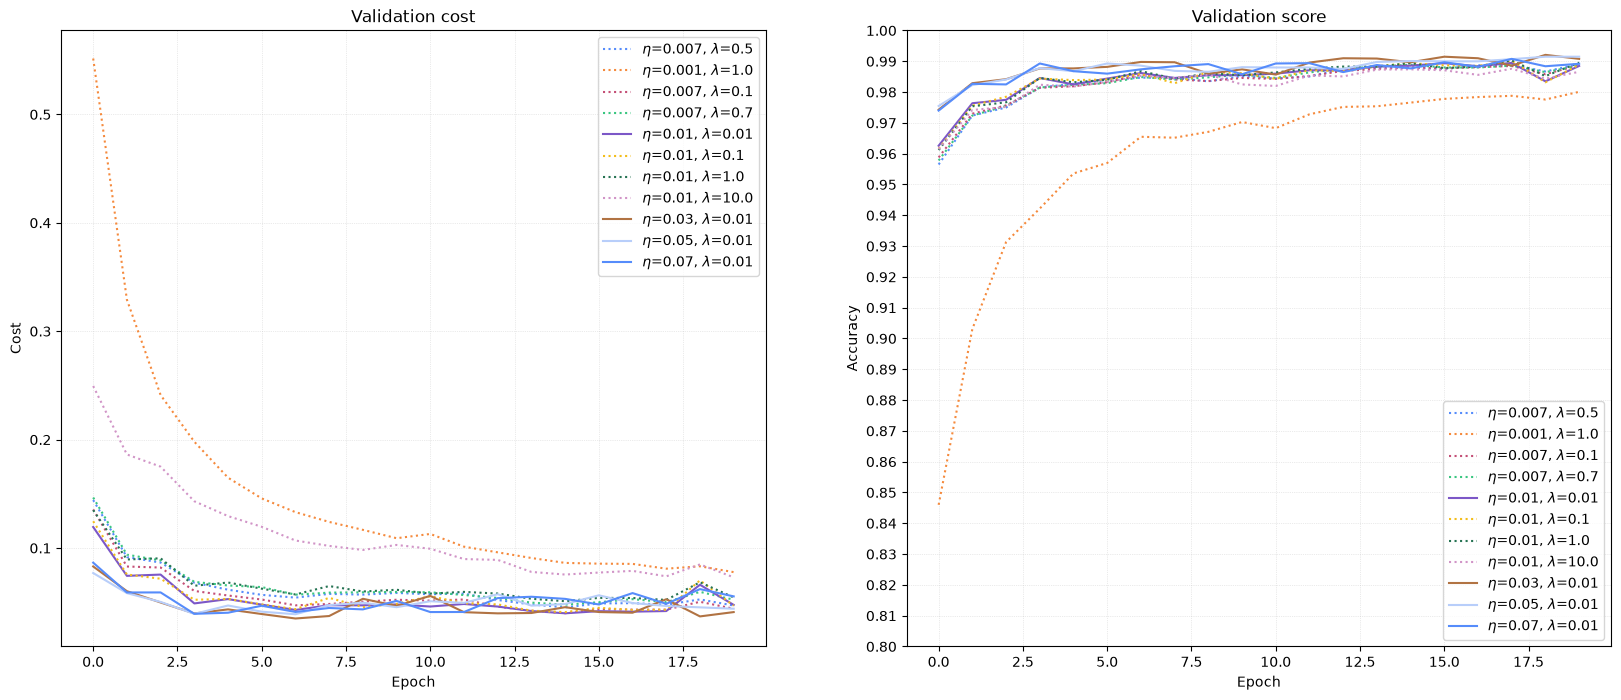

In [199]:
titles = ['Validation cost', 'Validation score']
ylabels = ['Cost', 'Accuracy']
legend_locs = ['upper right', 'lower right']
fig,axs = plt.subplots(1,2,figsize=(20,8))
for key,record in results.items():
    eta, lmbda = key
    for title, ylabel, data, ax, legend_loc in zip(titles, ylabels, record, axs.flat, legend_locs):
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.grid(visible=True, axis="both", ls=":", alpha=0.5)
        if ax == axs.flat[-1]:
            ax.set_yticks(np.arange(0.8,1.01,0.01))
            ax.set_ylim(0.8,1.0)
        ls = '-' if lmbda == 1e-2 else ':'
        alpha = 1.0 if lmbda == 1e-2 else 0.5
        ax.plot(range(len(data)), data, ls=ls, label=rf'$\eta$={eta}, $\lambda$={lmbda}')
        ax.legend(loc=legend_loc)
plt.show()

In [200]:
results60 = {}
for eta in [3e-2, 5e-2]:
    net = NeuralNet([
        ConvPoolLayer((20,1,5,5), (1,28,28), activation_fn=relu, random_state=1),
        ConvPoolLayer((40, 20, 5, 5), (20,12,12), activation_fn=relu, random_state=1),
        FullyConnectedLayer(40 * 4 * 4, 100, activation_fn=relu, random_state=1),
        SoftMaxLayer(100, 10, random_state=1),
    ])

    lmbda = 1e-2
    print(f'TRAINING WITH ETA={eta}, LAMBDA={lmbda}')
    print('===========================================')
    results60[(eta,lmbda)] = [*net.sgd((X_train, y_train), (X_val, y_val), (X_test, y_test), 60, 10, eta, lmbda, random_state=1)]
    print('===========================================')

TRAINING WITH ETA=0.03, LAMBDA=0.01
Training mini-batch number 0
Training mini-batch number 1000
Training mini-batch number 2000
Training mini-batch number 3000
Training mini-batch number 4000
Epoch 0: validation accuracy 97.43%
This is the best validation accuracy to date.
Training mini-batch number 5000
Training mini-batch number 6000
Training mini-batch number 7000
Training mini-batch number 8000
Training mini-batch number 9000
Epoch 1: validation accuracy 98.29%
This is the best validation accuracy to date.
Training mini-batch number 10000
Training mini-batch number 11000
Training mini-batch number 12000
Training mini-batch number 13000
Training mini-batch number 14000
Epoch 2: validation accuracy 98.42%
This is the best validation accuracy to date.
Training mini-batch number 15000
Training mini-batch number 16000
Training mini-batch number 17000
Training mini-batch number 18000
Training mini-batch number 19000
Epoch 3: validation accuracy 98.77%
This is the best validation accurac

In [220]:
# EXPANDED MNIST
import pickle
import random
import gzip

X, y = load_examples_mnist(n_samples=60000,)
training_data = [X[:50000], y[:50000]]
validation_data = [X[50000:], y[50000:]]

test_data = list(load_examples_mnist(n_samples=10000,
                                    images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                    labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte'))


expanded_training_pairs = []
j = 0
for x,y in zip(training_data[0], training_data[1]):
    expanded_training_pairs.append((x,y))
    image = np.reshape(x, (-1, 28))
    j += 1
    if j % 1000 == 0:
        print("Expanding image number", j)
    for d, axis, index_position, index in [
        (1, 0, 'first', 0),
        (-1, 0, 'first', 27),
        (1, 1, 'last', 0),
        (-1, 1, 'last', 27),]:
        new_img = np.roll(image, d, axis)
        if index_position == "first":
            new_img[index, :] = np.zeros(28)
        else:
            new_img[:, index] = np.zeros(28)
        expanded_training_pairs.append((np.reshape(new_img, 784), y))
random.shuffle(expanded_training_pairs)
expanded_training_data = [list(d) for d in zip(*expanded_training_pairs)]
print("Saving expanded data.")
with gzip.open("data/mnist_expanded.pkl.gz", "wb") as f:
    pickle.dump((expanded_training_data, validation_data, test_data), f, protocol=pickle.HIGHEST_PROTOCOL)

Expanding image number 1000
Expanding image number 2000
Expanding image number 3000
Expanding image number 4000
Expanding image number 5000
Expanding image number 6000
Expanding image number 7000
Expanding image number 8000
Expanding image number 9000
Expanding image number 10000
Expanding image number 11000
Expanding image number 12000
Expanding image number 13000
Expanding image number 14000
Expanding image number 15000
Expanding image number 16000
Expanding image number 17000
Expanding image number 18000
Expanding image number 19000
Expanding image number 20000
Expanding image number 21000
Expanding image number 22000
Expanding image number 23000
Expanding image number 24000
Expanding image number 25000
Expanding image number 26000
Expanding image number 27000
Expanding image number 28000
Expanding image number 29000
Expanding image number 30000
Expanding image number 31000
Expanding image number 32000
Expanding image number 33000
Expanding image number 34000
Expanding image number 

In [229]:
def vectorize(j):
    e = np.zeros(10)
    e[j] = 1.0
    return e

with gzip.open("data/mnist_expanded.pkl.gz", "rb") as f:
    loaded_data = pickle.load(f)
training_data, validation_data, test_data = loaded_data
X_train, y_train = training_data
X_val, y_val = validation_data
X_test, y_test = [torch.Tensor(d).float().to(device) for d in test_data]

X_train = torch.Tensor(X_train).float().to(device) / 255.
y_train = torch.Tensor([vectorize(y) for y in y_train]).float().to(device)
X_val = torch.Tensor(X_val).float().to(device) / 255.
y_val = torch.Tensor([vectorize(y) for y in y_val]).float().to(device)

print(f'training data: X:{X_train.shape, X_train.dtype}, y:{y_train.shape, y_train.dtype}')
print(f'validation data: X:{X_val.shape, X_val.dtype}, y:{y_val.shape, y_val.dtype}')
print(f'test data: X:{X_test.shape, X_test.dtype}, y:{y_test.shape, y_test.dtype}')

training data: X:(torch.Size([250000, 784]), torch.float32), y:(torch.Size([250000, 10]), torch.float32)
validation data: X:(torch.Size([10000, 784]), torch.float32), y:(torch.Size([10000, 10]), torch.float32)
test data: X:(torch.Size([10000, 784]), torch.float32), y:(torch.Size([10000]), torch.float32)


In [236]:
net = NeuralNet([
    ConvPoolLayer((20,1,5,5), (1,28,28), activation_fn=relu, random_state=1),
    ConvPoolLayer((40, 20, 5, 5), (20,12,12), activation_fn=relu, random_state=1),
    FullyConnectedLayer(40 * 4 * 4, 100, activation_fn=relu, random_state=1),
    SoftMaxLayer(100, 10, random_state=1),
])
eta = 3e-2
lmbda = 1e-2
results60[(0,0)] = [*net.sgd((X_train, y_train), (X_val, y_val), (X_test, y_test), 60, 10, eta, lmbda, random_state=1)]

Training mini-batch number 0
Training mini-batch number 1000
Training mini-batch number 2000
Training mini-batch number 3000
Training mini-batch number 4000
Training mini-batch number 5000
Training mini-batch number 6000
Training mini-batch number 7000
Training mini-batch number 8000
Training mini-batch number 9000
Training mini-batch number 10000
Training mini-batch number 11000
Training mini-batch number 12000
Training mini-batch number 13000
Training mini-batch number 14000
Training mini-batch number 15000
Training mini-batch number 16000
Training mini-batch number 17000
Training mini-batch number 18000
Training mini-batch number 19000
Training mini-batch number 20000
Training mini-batch number 21000
Training mini-batch number 22000
Training mini-batch number 23000
Training mini-batch number 24000
Epoch 0: validation accuracy 98.57%
This is the best validation accuracy to date.
Training mini-batch number 25000
Training mini-batch number 26000
Training mini-batch number 27000
Trainin

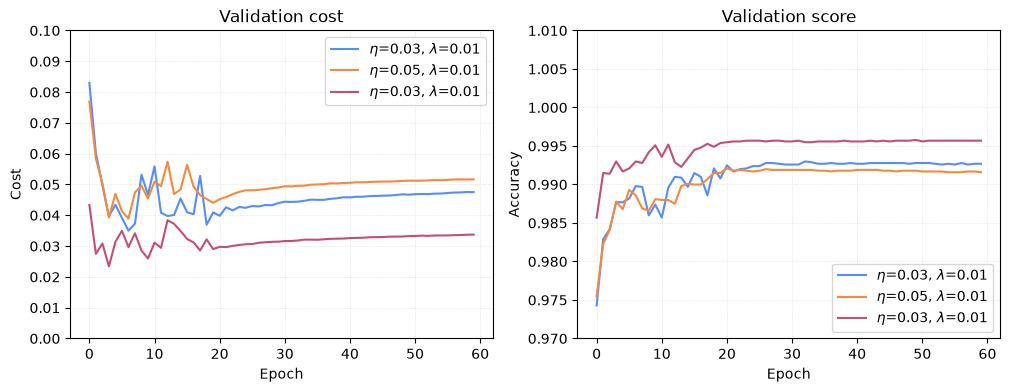

In [238]:
titles = ['Validation cost', 'Validation score']
ylabels = ['Cost', 'Accuracy']
legend_locs = ['upper right', 'lower right']
ylims = [(0,0.1), (0.97,1)]
yticks = [np.arange(0.0,0.101,0.01), np.arange(0.97,1.01,0.005)]
colors = ['blue', 'orange', 'green']
fig,axs = plt.subplots(1,2,figsize=(12,4))
for item,color in zip(results60.items(), colors):
    key, record = item
    eta, lmbda = key
    if key == (0,0):
        eta, lmbda = 3e-2, 1e-2
    for title, ylabel, data, ax, legend_loc, ylim, ytick in zip(titles, ylabels, record, axs.flat, legend_locs, ylims, yticks):
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.set_ylim(*ylim)
        ax.set_yticks(ytick)
        ax.grid(visible=True, axis="both", ls=":", alpha=0.5)
        ax.plot(range(len(data)), data, label=rf'$\eta$={eta}, $\lambda$={lmbda}')
        ax.legend(loc=legend_loc)
plt.show()

In [247]:
num_test_batches = len(X_test)//10 + len(X_test)%10
test_score = 0.
with torch.no_grad():
    for i in range(num_test_batches):
        X_test_mb = X_test[i*10:(i+1)*10]
        y_test_mb = y_test[i*10:(i+1)*10]

        activation = X_test_mb / 255.
        for layer in net.layers:
            layer.forward(activation, len(X_test_mb))
            activation = layer.output

        test_score += net.layers[-1].accuracy(y_test_mb) * len(X_test_mb) / len(X_test)

print('Expanded MNIST:')
print(f' Test score: {test_score:.2%}')

Expanded MNIST:
 Test score: 99.45%


In [251]:
torch.save([p.detach().cpu() for p in net.params], 'models/expanded-mnist_c20x5x5_c40x5x5_f100_s10.pt')

In [259]:
neural_net_cfg = {
    'layers': {},
    'sgd': {
        'epochs': 60,
        'minibatch_size': 10,
        'eta': 3e-2,
        'lmbda': 1e-2,
        'random_state': 1
    },
}
for i,layer in enumerate(net.layers):
    layer_cfg = {}
    type_ = type(layer).__name__
    layer_cfg['type'] = type_
    if type_ == 'ConvPoolLayer':
        layer_cfg['filter_shape'] = list(layer.filter_shape)
        layer_cfg['image_shape'] = list(layer.image_shape)
        layer_cfg['activation_fn'] = layer.activation_fn.__name__
        layer_cfg['pool_size'] = list(layer.pool_size)
        layer_cfg['stride'] = layer.stride
        layer_cfg['seed'] = 1
    elif type_ == 'FullyConnectedLayer':
        layer_cfg['n_in'] = layer.n_in
        layer_cfg['n_out'] = layer.n_out
        layer_cfg['activation_fn'] = layer.activation_fn.__name__
        layer_cfg['p_dropout'] = layer.p_dropout
        layer_cfg['seed'] = 1
    elif type_ == 'SoftMaxLayer':
        layer_cfg['n_in'] = layer.n_in
        layer_cfg['n_out'] = layer.n_out
        layer_cfg['p_dropout'] = layer.p_dropout
        layer_cfg['seed'] = 1
    neural_net_cfg['layers'][i+1] = layer_cfg

In [261]:
import json
with open('models/expanded-mnist_c20x5x5_c40x5x5_f100_s10_cfg.json', "w") as f:
    json.dump(neural_net_cfg, f)